The notebook below studies the Nepal's earthquake severity index of Nepal. The dataset was downloaded from kaggle.com

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

%matplotlib inline

In [14]:
# Loading dataset
earthquake_data = pd.read_csv('data/nepal-earthquake-severity-index-latest.csv')

In [15]:

# Checking shape
print("Shape: \n", earthquake_data.shape)

Shape: 
 (3986, 12)


In [16]:
print("Info: \n", earthquake_data.info())

<class 'pandas.DataFrame'>
RangeIndex: 3986 entries, 0 to 3985
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   P_CODE               3985 non-null   str    
 1   VDC_NAME             3985 non-null   str    
 2   DISTRICT             3985 non-null   str    
 3   REGION               3985 non-null   str    
 4   Hazard (Intensity)   3985 non-null   float64
 5   Exposure             3985 non-null   float64
 6   Housing              3985 non-null   float64
 7   Poverty              3985 non-null   float64
 8   Vulnerability        3985 non-null   float64
 9   Severity             3985 non-null   float64
 10  Severity Normalized  3985 non-null   float64
 11  Severity category    3985 non-null   str    
dtypes: float64(7), str(5)
memory usage: 373.8 KB
Info: 
 None


In [17]:

print("Description: \n", earthquake_data.describe().T)

Description: 
                       count      mean       std   min     25%     50%     75%  \
Hazard (Intensity)   3985.0  0.320537  0.779937  0.00  0.0000  0.0100  0.1300   
Exposure             3985.0  0.067493  0.187551  0.00  0.0300  0.0500  0.0700   
Housing              3985.0  5.706522  1.953037  1.17  4.6400  5.6100  6.8500   
Poverty              3985.0  5.481854  2.270975  0.00  3.3300  5.6200  7.3500   
Vulnerability        3985.0  5.594635  1.450817  1.62  4.5900  5.5500  6.6600   
Severity             3985.0  0.248720  0.298756  0.00  0.0500  0.1400  0.3600   
Severity Normalized  3985.0  0.510221  0.612652  0.00  0.0941  0.2862  0.7448   

                       max  
Hazard (Intensity)   10.00  
Exposure             10.00  
Housing               9.94  
Poverty              10.00  
Vulnerability         8.83  
Severity              4.88  
Severity Normalized  10.00  


In [18]:
print(earthquake_data.isnull().sum())

P_CODE                 1
VDC_NAME               1
DISTRICT               1
REGION                 1
Hazard (Intensity)     1
Exposure               1
Housing                1
Poverty                1
Vulnerability          1
Severity               1
Severity Normalized    1
Severity category      1
dtype: int64


In [19]:
print(earthquake_data.head())

         P_CODE            VDC_NAME   DISTRICT   REGION  Hazard (Intensity)  \
0  C-BAG-27-031       KathmanduN.P.  Kathmandu  Central                2.17   
1  C-BAG-25-027        LalitpurN.P.   Lalitpur  Central                1.72   
2  C-NAR-35-005      BharatpurN. P.   Chitawan  Central                2.21   
3  C-BAG-26-012  MadhyapurThimiN.P.  Bhaktapur  Central                2.45   
4  C-BAG-27-028             Jorpati  Kathmandu  Central                1.91   

   Exposure  Housing  Poverty  Vulnerability  Severity  Severity Normalized  \
0     10.00     8.86     1.82           5.34      4.88              10.0000   
1      2.26     8.40     0.82           4.61      2.62               5.3707   
2      1.47     5.38     2.53           3.96      2.34               4.8083   
3      0.85     8.23     0.89           4.56      2.12               4.3447   
4      0.87     8.86     1.82           5.34      2.07               4.2407   

  Severity category  
0           Highest  
1     

In [20]:
# Checking for row with null value
print(earthquake_data.isnull().any(axis=1))

0       False
1       False
2       False
3       False
4       False
        ...  
3981    False
3982    False
3983    False
3984    False
3985     True
Length: 3986, dtype: bool


### Data Cleaning

In [21]:
# Checking to make sure is the row has all null value
print(earthquake_data.iloc[3985])

P_CODE                 NaN
VDC_NAME               NaN
DISTRICT               NaN
REGION                 NaN
Hazard (Intensity)     NaN
Exposure               NaN
Housing                NaN
Poverty                NaN
Vulnerability          NaN
Severity               NaN
Severity Normalized    NaN
Severity category      NaN
Name: 3985, dtype: object


In [22]:
# dropping the row with null value
earthquake_data = earthquake_data.dropna()

In [23]:
earthquake_data.isnull().sum()

P_CODE                 0
VDC_NAME               0
DISTRICT               0
REGION                 0
Hazard (Intensity)     0
Exposure               0
Housing                0
Poverty                0
Vulnerability          0
Severity               0
Severity Normalized    0
Severity category      0
dtype: int64

In [24]:
print(earthquake_data.duplicated().sum())

0


In [25]:
earthquake_data.dtypes

P_CODE                     str
VDC_NAME                   str
DISTRICT                   str
REGION                     str
Hazard (Intensity)     float64
Exposure               float64
Housing                float64
Poverty                float64
Vulnerability          float64
Severity               float64
Severity Normalized    float64
Severity category          str
dtype: object

In [26]:
earthquake_data['DISTRICT'].unique()

<StringArray>
[     'Kathmandu',       'Lalitpur',       'Chitawan',      'Bhaktapur',
         'Gorkha',       'Sindhuli', 'Kavrepalanchok',      'Makwanpur',
        'Nuwakot',         'Tanahu',    'Nawalparasi',        'Dhading',
        'Dolakha',          'Kaski',        'Sarlahi',      'Mahottari',
  'Sindhupalchok',          'Parsa',        'Dhanusa',       'Rautahat',
      'Ramechhap',           'Bara',         'Rasuwa',        'Lamjung',
         'Morang',      'Rupandehi',         'Siraha',       'Udayapur',
        'Sunsari',     'Kapilbastu',        'Saptari',        'Syangja',
          'Palpa',    'Okhaldhunga',           'Dang',  'Sankhuwasabha',
          'Jhapa',        'Baglung',         'Parbat',          'Banke',
         'Manang',        'Bhojpur',        'Khotang',     'Solukhumbu',
           'Ilam',          'Gulmi',       'Dhankuta',        'Pyuthan',
      'Taplejung',         'Myagdi',      'Panchthar',          'Rukum',
          'Rolpa',         'Salyan', 

### DATA VISUALIZATION

Text(0.5, 1.0, 'Severity Distribution')

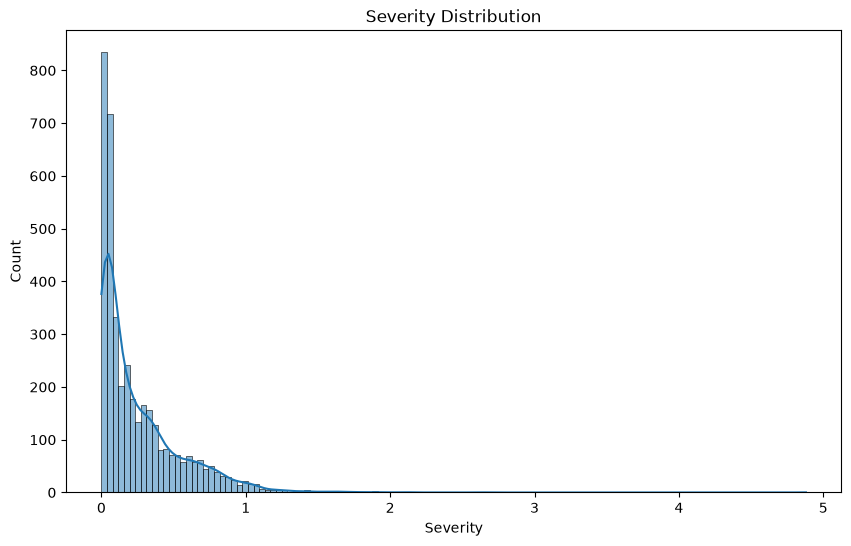

In [27]:
plt.figure(figsize=(10,6))
sns.histplot(data=earthquake_data, x='Severity', kde=True)
plt.title("Severity Distribution")

The earthquake severity distribution is highly skewed right indicating that the most of the areas in nepal have low earthquake severity (close to 0). with very few regions facing earthquake severity above 2. This sugguests that while earthquake risks exists in Nepal, extreme severity is faced bu very few concentrated areas only

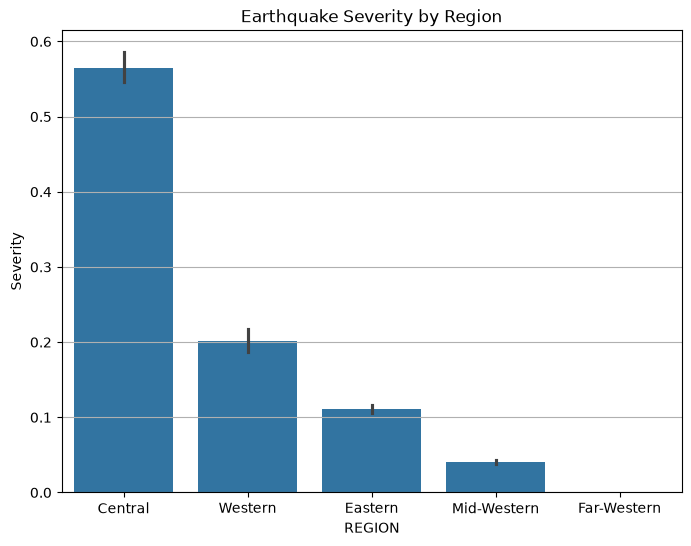

In [28]:
plt.figure(figsize=(8, 6))
sns.barplot(x=earthquake_data['REGION'], y=earthquake_data['Severity'])
plt.title('Earthquake Severity by Region')
plt.grid(True, axis='y')

In [29]:
earthquake_data.groupby('REGION')['Severity'].mean()

REGION
Central        0.564660
Eastern        0.111397
Far-Western    0.000660
Mid-Western    0.040412
Western        0.200978
Name: Severity, dtype: float64

The barplot compares earthquake severity across the five regions of Nepal. Central Nepal has the highest severity, at about 0.56, followed by Western Nepal at roughly 0.20 and the Eastern region at about 0.11. The Mid-Western region has a fairly low severity of around 0.04, and the Far-Western region has the lowest, close to 0. Central Nepal's severity is almost three times that of the Western region, which suggests that the earthquake affected the Central region the most.

<Axes: title={'center': 'Severity Category Count by District'}, xlabel='Severity category', ylabel='Severity Category Count'>

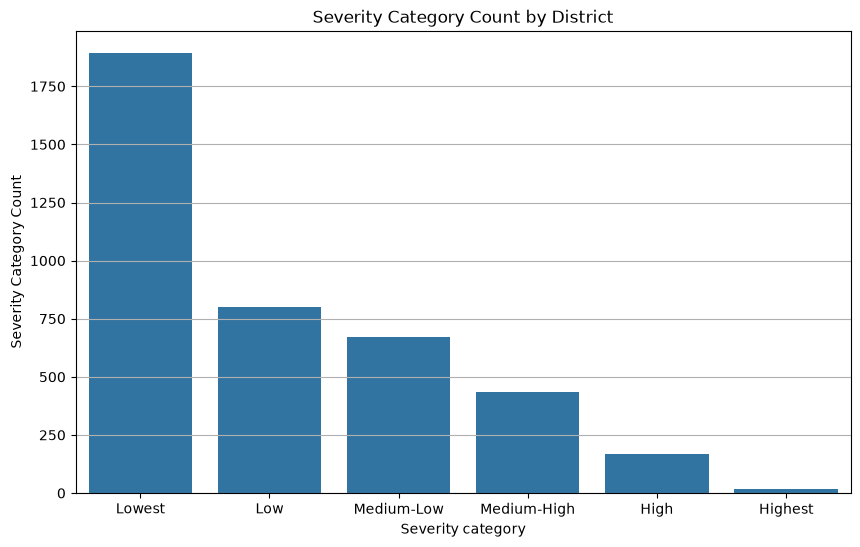

In [30]:
#make a chart of severity category count
counts = earthquake_data['Severity category'].value_counts()

plt.figure(figsize=(10, 6))
plt.title("Severity Category Count by District")
plt.ylabel('Severity Category Count')
plt.grid(True)
sns.barplot(x=counts.index, y= counts.values)

The bar chart shows the number of areas in Nepal classified under each earthquake severity category.

The majority of areas fall under the 'Lowest' severity category (~1900 areas), followed by 'Low' and 'Medium-Low'. This confirms the right-skewed distribution seen in the previous histogram. As severity increases, the number of areas decreases significantly — 'Highest' severity areas are extremely rare, with fewer than 50 areas across all of Nepal.

This suggests that while most of Nepal faces low earthquake risk, a small number of highly vulnerable areas — likely in densely populated regions like Kathmandu — require priority attention for disaster preparedness.

<Axes: title={'center': 'Top 10 Most Severe District'}, xlabel='DISTRICT', ylabel='Mean Earthquake Severity'>

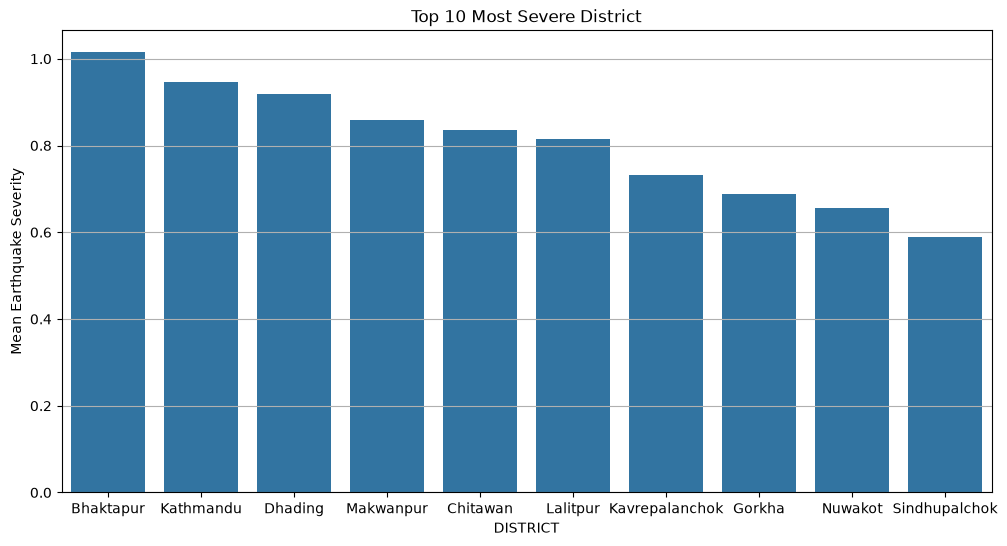

In [31]:
# Top 10 most severe districts
top_severity_districts = earthquake_data.groupby('DISTRICT')['Severity'].mean().nlargest(10)

plt.figure(figsize=(12,6))
plt.title("Top 10 Most Severe District")
plt.grid(True, axis='y')
plt.ylabel("Mean Earthquake Severity")
sns.barplot(x=top_severity_districts.index, y=top_severity_districts.values)

In [32]:
print(top_severity_districts)

DISTRICT
Bhaktapur         1.014444
Kathmandu         0.946780
Dhading           0.918400
Makwanpur         0.859545
Chitawan          0.836410
Lalitpur          0.815000
Kavrepalanchok    0.731556
Gorkha            0.687612
Nuwakot           0.656290
Sindhupalchok     0.589620
Name: Severity, dtype: float64


The bar chart shows the top 10 districts with the highest mean earthquake severity in Nepal.

Bhaktapur has the highest average severity (1.01), slightly exceeding Kathmandu (0.95).  Notably, most of the top 10 districts are from the Central region — Bhaktapur, Kathmandu, Dhading, Makwanpur, Lalitpur — suggesting that Central Nepal faces significantly higher  earthquake risk compared to other regions. Districts like Gorkha and Sindhupalchok also appear in the top 10, which aligns with the fact that the 2015 earthquake epicenter was in that area.

<Axes: xlabel='Hazard (Intensity)', ylabel='Severity'>

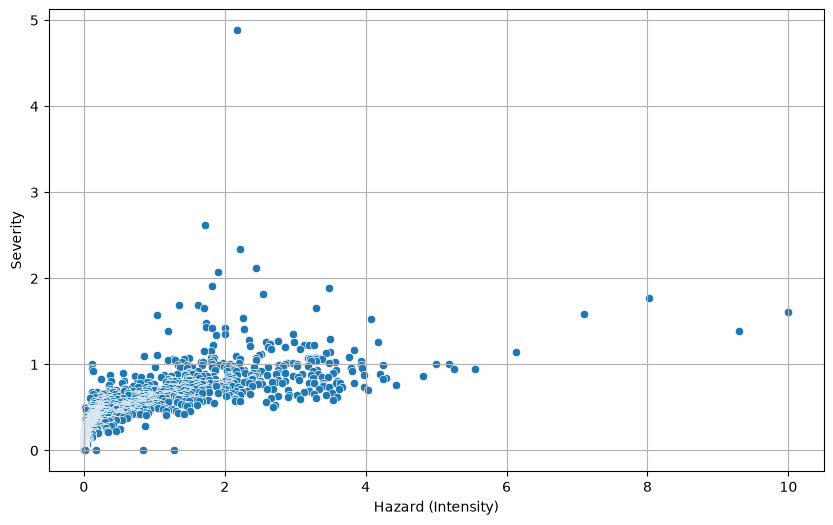

In [33]:
plt.figure(figsize=(10, 6))
plt.grid(True)
sns.scatterplot(x=earthquake_data['Hazard (Intensity)'], y=earthquake_data['Severity'])

The scatter plot compares earthquake severity with its hazard intensity in Nepal. There is a positive relationship, as hazard intensity increases, severity generally increases too. Most points are clustered on the left side of the plot, which shows that most earthquakes in the data have low intensity (below 4) and low severity (below 1.5).

However, the relationship is not perfectly consistent. Between intensities of 1 and 4, severity varies a lot, and one outlier reaches nearly 5. At the same time, the events with the highest intensity (around 7 to 10) have only moderate severity, about 1.4 to 1.8. This means that higher hazard intensity does not always lead to higher severity.

In conclusion, hazard intensity is not the only factor that determines earthquake severity. Other variables, such as location or population, probably also play a role.

Text(0.5, 1.0, 'Relationship between Poverty and Vulnerability')

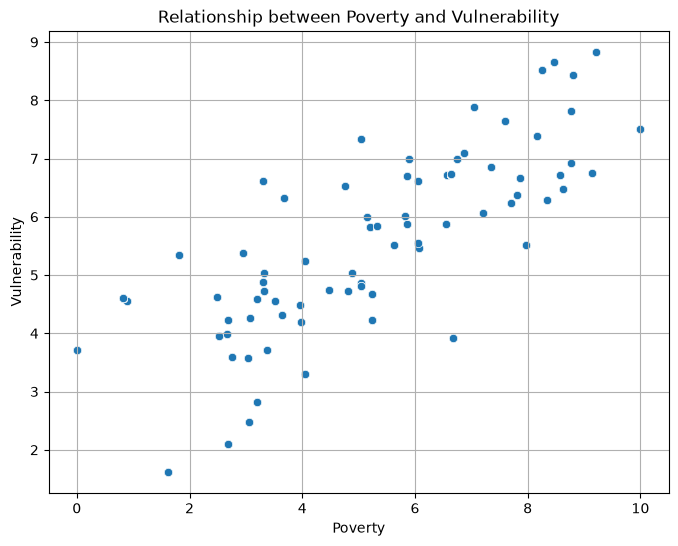

In [34]:
plt.figure(figsize=(8,6))
plt.grid(True)
sns.scatterplot(x=earthquake_data['Poverty'], y=earthquake_data['Vulnerability'])
plt.title("Relationship between Poverty and Vulnerability")

The scatter plot shows the relationship between Poverty and Vulnerability for earthquake risk in Nepal.

There is a positive relationship, vulnerability increases with increasing Poverty. 

Areas with Poverty below 4 most have vulnerability between 2 to 5.5 and areas with Poverty between 4-8 have the vulnerability between 4 to 8. Whereas area with poverty above 8 has vulnerability reaching nearly to 9. 

The relationship between Poverty and Vulnerability seems moderately strong and roughly linear. This suggests that poorer areas in Nepal are significantly more vulnerable to 
earthquake damage.

,mean,median,max
REGION,,,
Central,0.080082,0.05,10.00
Eastern,0.065259,0.04,2.06
Far-Western,0.065838,0.04,1.07
Mid-Western,0.061667,0.05,0.74
Western,0.056917,0.04,2.62


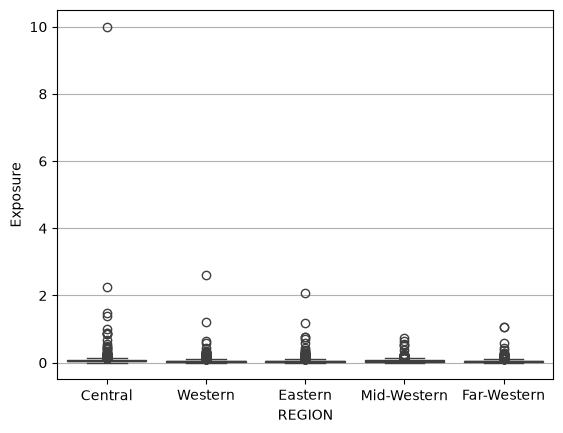

In [35]:
plt.grid(True)
sns.boxplot(x=earthquake_data['REGION'], y=earthquake_data['Exposure'])

earthquake_data.groupby('REGION')['Exposure'].agg(['mean', 'median', 'max'])

The plot shows the exposure/density of the 5 different regions of Nepal.

In all regions, the exposure is very low in all the regions of Nepal (near to 0). The main difference lies in their outliers, Central region has the most extreme value(10), followed by Western 2.6 and Eastern (about 2), Far-Western (roughly 1) and Mid-Western has the lowest maximum(0.7).

This suggests that the exposure is concentrated in a few highly exposed areas rather than being evenly spread out.


### Conclusion

This analysis explored Nepal Earthquake Severity Index dataset containing 3965 data across Nepal to understand the distribution and factors contributing to earthquake risk.

**Key Findings**

1. Most of the areas in Nepal have very low earthquake severity, with the distribution mostly skewed right. Only a small number of area face high severity.

2. Central Nepal is significantly more at risk for earthquake compared to other regions as it has highest earthquake severity, more high-severity districts (Bhaktapur, Kathmandu, Lalitpur) and most extreme exposure value.

3. Poverty and Vulnerability have a moderately positive relationship, meaning poorer areas tends to be more vulnerable to earthquake damage, likely due to weak infrastructure and other factors.